In [16]:
import xarray as xr
import numpy as np
import pandas as pd
import sys
import shutil
import os
import matplotlib.pyplot as plt

In [17]:
RTOBSPATH = "/Net/Groups/BSI/work_scratch/ppapastefanou/data/Fluxnet_detail/eval_processed"

In [18]:
df_sap24 = pd.read_csv(os.path.join(RTOBSPATH, "DE-Hai_forcing_30min_20230101_20251227.csv"))
df_sap24['datetime'] = pd.to_datetime(df_sap24['datetime'])
df_sap24['time'] = df_sap24['datetime'].dt.time
df_sapfix24  = df_sap24
df_sapfix24['datetime'] = df_sapfix24['datetime'] + pd.Timedelta(hours=2)
# If you still need to extract the time afterward:
df_sapfix24['time'] = df_sapfix24['datetime'].dt.time

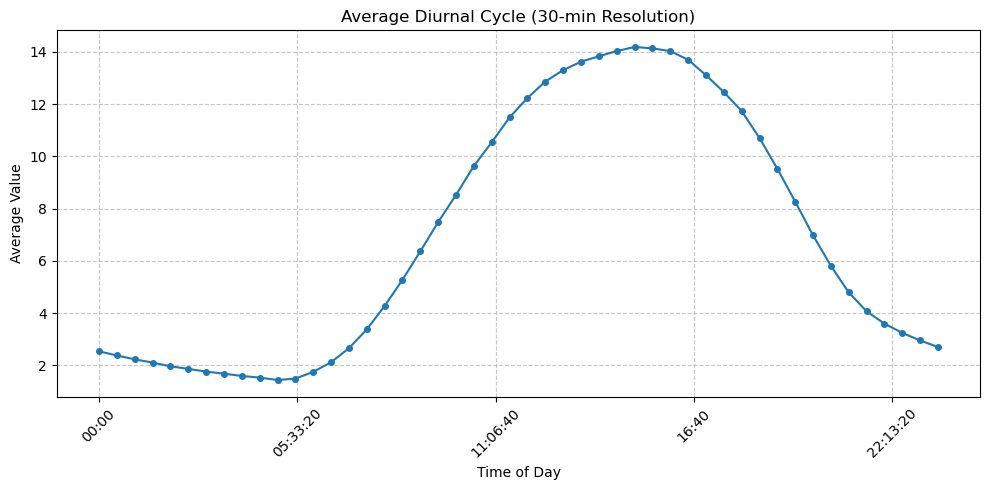

In [19]:


# 3. Calculate the mean for each time slot
diurnal_cycle_a = df_sap24.groupby('time')['Ji_Fasy'].mean()

# 4. Plot
plt.figure(figsize=(10, 5))
diurnal_cycle_a.plot(kind='line', marker='o', markersize=4)
plt.title('Average Diurnal Cycle (30-min Resolution)')
plt.xlabel('Time of Day')
plt.ylabel('Average Value')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

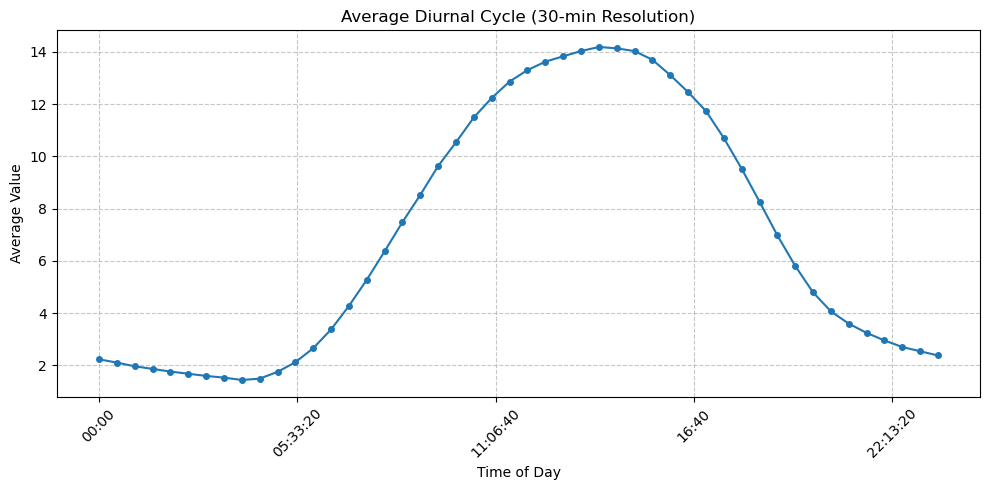

In [8]:


# 3. Calculate the mean for each time slot
diurnal_cycle = df_sap24.groupby('time')['Ji_Fasy'].mean()

# 4. Plot
plt.figure(figsize=(10, 5))
diurnal_cycle.plot(kind='line', marker='o', markersize=4)
plt.title('Average Diurnal Cycle (30-min Resolution)')
plt.xlabel('Time of Day')
plt.ylabel('Average Value')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
df= pd.read_csv("/Net/Groups/BSI/work_scratch/ppapastefanou/data/Fluxnet_detail/QUINCY_DE-Hai_1901_2024.dat", sep='\s+', index_col=None, skiprows=[1])

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_24700/2601888458.py:1: SyntaxWarning: invalid escape sequence '\s'
  df= pd.read_csv("/Net/Groups/BSI/work_scratch/ppapastefanou/data/Fluxnet_detail/QUINCY_DE-Hai_1901_2024.dat", sep='\s+', index_col=None, skiprows=[1])


In [21]:
diurnal_cycle_a

time
00:00:00     2.537972
00:30:00     2.378042
01:00:00     2.231523
01:30:00     2.105192
02:00:00     1.964549
02:30:00     1.864945
03:00:00     1.760755
03:30:00     1.679644
04:00:00     1.595161
04:30:00     1.529811
05:00:00     1.440224
05:30:00     1.490695
06:00:00     1.750257
06:30:00     2.118273
07:00:00     2.655964
07:30:00     3.372380
08:00:00     4.272972
08:30:00     5.273642
09:00:00     6.363990
09:30:00     7.482161
10:00:00     8.524675
10:30:00     9.630207
11:00:00    10.536656
11:30:00    11.489719
12:00:00    12.232233
12:30:00    12.860584
13:00:00    13.298879
13:30:00    13.619354
14:00:00    13.826485
14:30:00    14.027076
15:00:00    14.183357
15:30:00    14.131195
16:00:00    14.025742
16:30:00    13.694111
17:00:00    13.106426
17:30:00    12.456563
18:00:00    11.731389
18:30:00    10.699699
19:00:00     9.523365
19:30:00     8.262627
20:00:00     6.971896
20:30:00     5.805004
21:00:00     4.790883
21:30:00     4.064244
22:00:00     3.595243
22:30

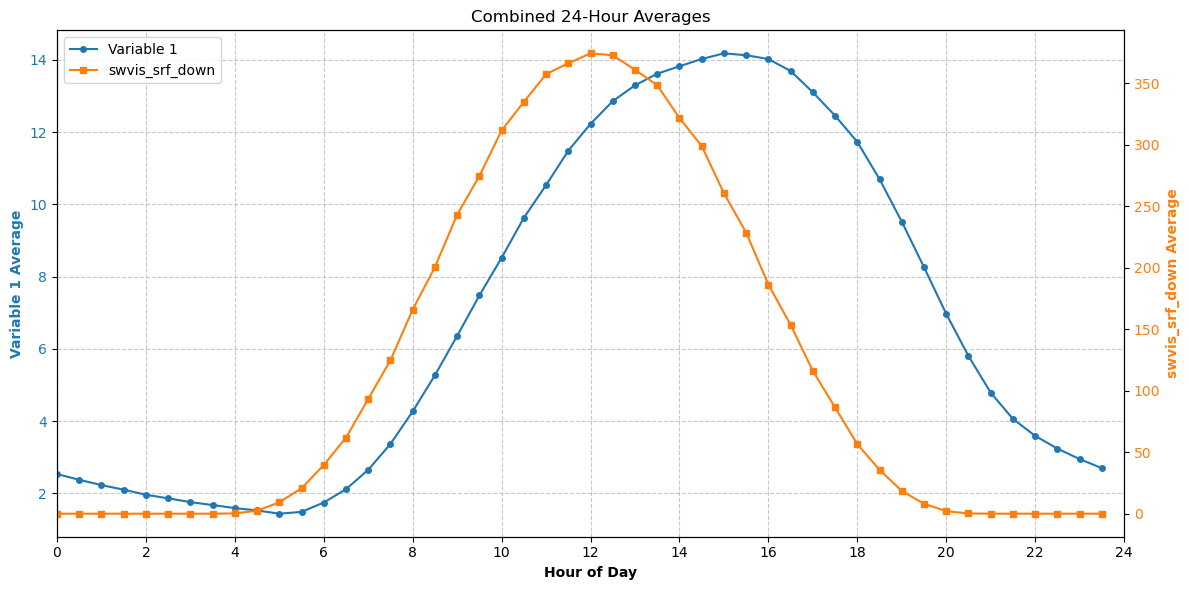

In [22]:
diurnal_cycle = df.groupby('hour')['swvis_srf_down'].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Variable 1 on the Left Y-Axis
color1 = 'tab:blue'
ax1.set_xlabel('Hour of Day', fontweight='bold')
ax1.set_ylabel('Variable 1 Average', color=color1, fontweight='bold')
line1 = ax1.plot(np.arange(0,24,0.5), diurnal_cycle_a.values, color=color1, marker='o', markersize=4, label='Variable 1')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.7) # Grid attached to the left axis

# Create the Secondary Y-Axis
ax2 = ax1.twinx()

# Plot Radiation on the Right Y-Axis
color2 = 'tab:orange'
ax2.set_ylabel('swvis_srf_down Average', color=color2, fontweight='bold')
line2 = ax2.plot(diurnal_cycle.index, diurnal_cycle.values, color=color2, marker='s', markersize=4, label='swvis_srf_down')
ax2.tick_params(axis='y', labelcolor=color2)

# --- 4. Clean up and Formatting ---
# Combine legends from both axes so they live in one box
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Combined 24-Hour Averages')
ax1.set_xlim(0, 24)
ax1.set_xticks(range(0, 25, 2)) # X-axis labels every 2 hours

fig.tight_layout() # Prevents labels from getting cut off
plt.show()

In [23]:
df_sapfix24[['datetime', "Ji_Fasy", "Ji_sd_Fasy"]]
df_sapfix24[['datetime', "Ji_Fasy", "Ji_sd_Fasy"]].to_csv("/Net/Groups/BSI/work_scratch/ppapastefanou/data/Fluxnet_detail/eval_processed/Sapflow2023-2024_offset.csv", index=False)

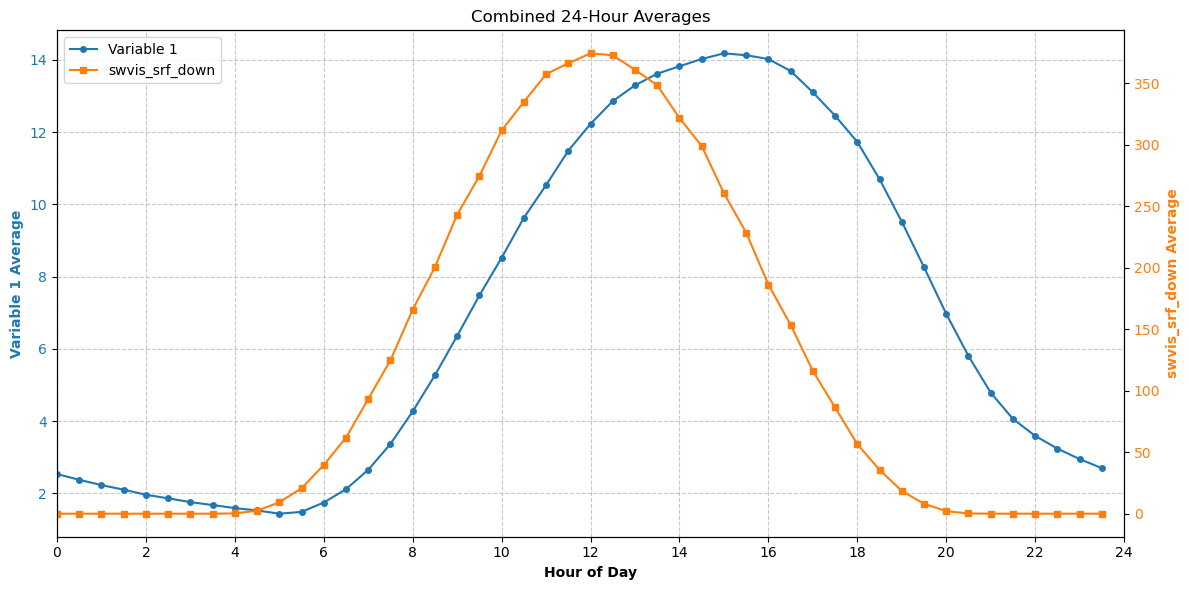

In [24]:
diurnal_cycle = df.groupby('hour')['swvis_srf_down'].mean()
diurnal_cycle_a = df_sapfix24.groupby('time')['Ji_Fasy'].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Variable 1 on the Left Y-Axis
color1 = 'tab:blue'
ax1.set_xlabel('Hour of Day', fontweight='bold')
ax1.set_ylabel('Variable 1 Average', color=color1, fontweight='bold')
line1 = ax1.plot(np.arange(0,24,0.5), diurnal_cycle_a.values, color=color1, marker='o', markersize=4, label='Variable 1')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.7) # Grid attached to the left axis

# Create the Secondary Y-Axis
ax2 = ax1.twinx()

# Plot Radiation on the Right Y-Axis
color2 = 'tab:orange'
ax2.set_ylabel('swvis_srf_down Average', color=color2, fontweight='bold')
line2 = ax2.plot(diurnal_cycle.index, diurnal_cycle.values, color=color2, marker='s', markersize=4, label='swvis_srf_down')
ax2.tick_params(axis='y', labelcolor=color2)

# --- 4. Clean up and Formatting ---
# Combine legends from both axes so they live in one box
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Combined 24-Hour Averages')
ax1.set_xlim(0, 24)
ax1.set_xticks(range(0, 25, 2)) # X-axis labels every 2 hours

fig.tight_layout() # Prevents labels from getting cut off
plt.show()